In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import sklearn
import os
import shutil
import cv2
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Flatten, Dense, Dropout, MaxPooling2D, BatchNormalization
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.callbacks import EarlyStopping, Callback , ModelCheckpoint
from tensorflow.keras.metrics import Accuracy,binary_crossentropy, FalsePositives, FalseNegatives, TruePositives, TrueNegatives
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
df = pd.read_csv("../input/breakhis/Folds.csv")

In [3]:
path = "./BreaKHis_v1/"
classes = ["benign","malign"]

In [4]:
df = df.rename(columns = {"filename":"path"})

In [5]:
df.head(10)

,fold,mag,grp,path
0,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
1,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
2,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
3,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
4,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
5,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
6,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
7,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
8,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
9,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...


In [6]:
df['filename'] = df['path'].apply(lambda x:x.split("/")[-1])
df["label"] = df['path'].apply(lambda x: x.split("/")[3])

In [7]:
os.makedirs("../Cancer/")

In [8]:
for p in df['path']:
    src = "../input/breakhis/BreaKHis_v1/" + p
    dest = "../Cancer/"
    dest = os.path.join(dest,src.split("/")[7]+ "_" + src.split("/")[-1])
    shutil.copyfile(src,dest)    

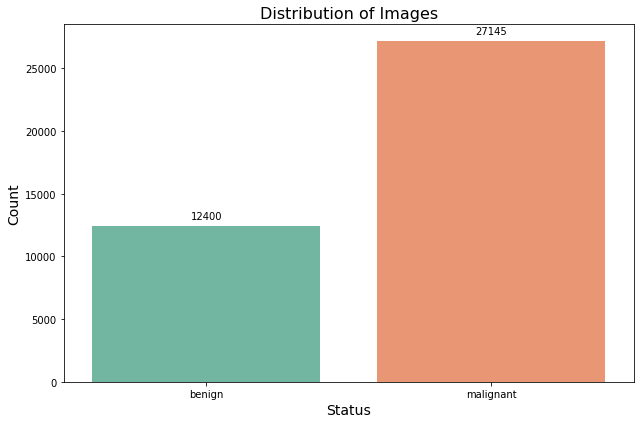

In [11]:
plt.figure(figsize=(9,6))
sns.countplot(data=df, x='label', palette='Set2')
plt.title("Distribution of Images", fontsize=16)
plt.xlabel("Status", fontsize=14)
plt.ylabel("Count", fontsize=14)

for p in plt.gca().patches:
    plt.gca().annotate(format(p.get_height(), '.0f'), 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha = 'center', va = 'center', 
                       xytext = (0, 10), textcoords = 'offset points')

plt.tight_layout()
plt.show()

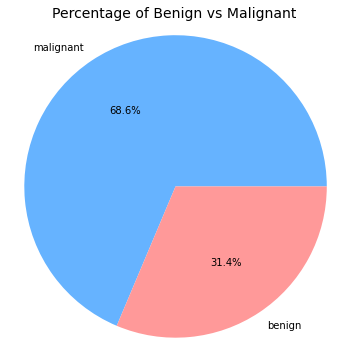

In [12]:
tumor_counts = df['label'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(tumor_counts, labels=tumor_counts.index, autopct='%1.1f%%', colors=["#66b3ff","#ff9999"])
plt.title("Percentage of Benign vs Malignant", fontsize=14)
plt.axis('equal')
plt.show()

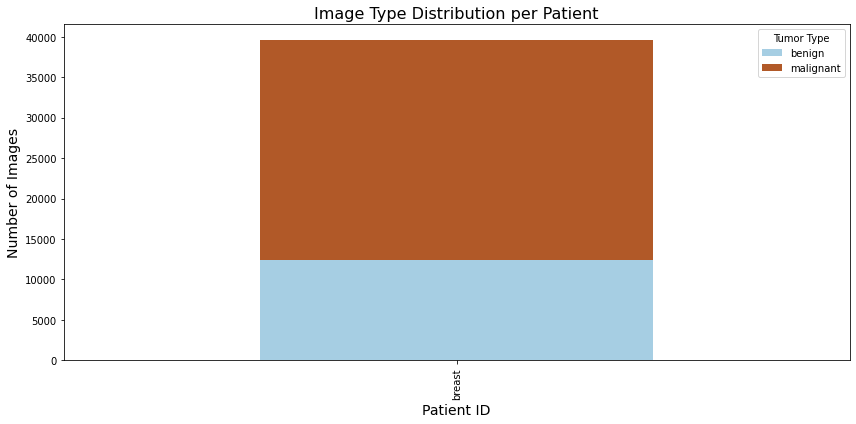

In [13]:
df['patient_id'] = df['path'].apply(lambda x: x.split("/")[2])
grouped = df.groupby(['patient_id', 'label']).size().unstack(fill_value=0)

grouped.plot(kind='bar', stacked=True, figsize=(12,6), colormap='Paired')
plt.title('Image Type Distribution per Patient', fontsize=16)
plt.xlabel('Patient ID', fontsize=14)
plt.ylabel('Number of Images', fontsize=14)
plt.legend(title='Tumor Type')
plt.tight_layout()
plt.show()

In [14]:
df['file_loc'] = df['label'] + "_" + df['filename']
df['class'] = df['label'].apply(lambda x: 0 if x =='benign' else 1)

In [15]:
def get_image_dimensions(filepath):
    try:
        img = cv2.imread(filepath)
        h, w = img.shape[:2]
        return w, h, w * h
    except:
        return 0, 0, 0

df['full_path'] = "../Cancer/" + df['file_loc']
df[['width', 'height', 'resolution']] = df['full_path'].apply(
    lambda x: pd.Series(get_image_dimensions(x))
)

df.head()

,fold,mag,grp,path,filename,label,patient_id,file_loc,class,full_path,width,height,resolution
0,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...,SOB_B_A-14-22549AB-100-001.png,benign,breast,benign_SOB_B_A-14-22549AB-100-001.png,0,../Cancer/benign_SOB_B_A-14-22549AB-100-001.png,700,460,322000
1,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...,SOB_B_A-14-22549AB-100-002.png,benign,breast,benign_SOB_B_A-14-22549AB-100-002.png,0,../Cancer/benign_SOB_B_A-14-22549AB-100-002.png,700,460,322000
2,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...,SOB_B_A-14-22549AB-100-003.png,benign,breast,benign_SOB_B_A-14-22549AB-100-003.png,0,../Cancer/benign_SOB_B_A-14-22549AB-100-003.png,700,460,322000
3,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...,SOB_B_A-14-22549AB-100-004.png,benign,breast,benign_SOB_B_A-14-22549AB-100-004.png,0,../Cancer/benign_SOB_B_A-14-22549AB-100-004.png,700,460,322000
4,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...,SOB_B_A-14-22549AB-100-005.png,benign,breast,benign_SOB_B_A-14-22549AB-100-005.png,0,../Cancer/benign_SOB_B_A-14-22549AB-100-005.png,700,460,322000


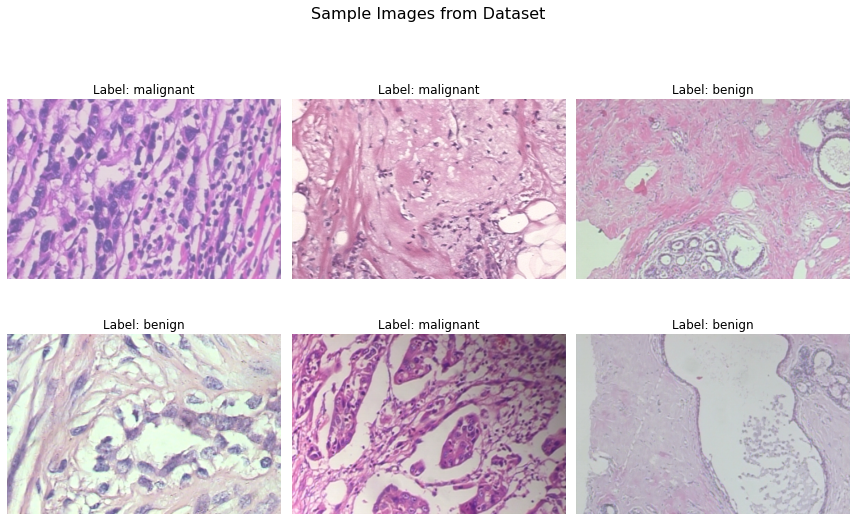

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
sample_df = df.sample(6)

for ax, (_, row) in zip(axes.flatten(), sample_df.iterrows()):
    img = cv2.imread(row['full_path'])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"Label: {row['label']}")
    ax.axis('off')

plt.tight_layout()
plt.suptitle("Sample Images from Dataset", fontsize=16)
plt.subplots_adjust(top=0.9)
plt.show()

In [17]:
benign_df = df[df['label'] == 'benign']
malignant_df = df[df['label'] == 'malignant']

# Cancer-free Image

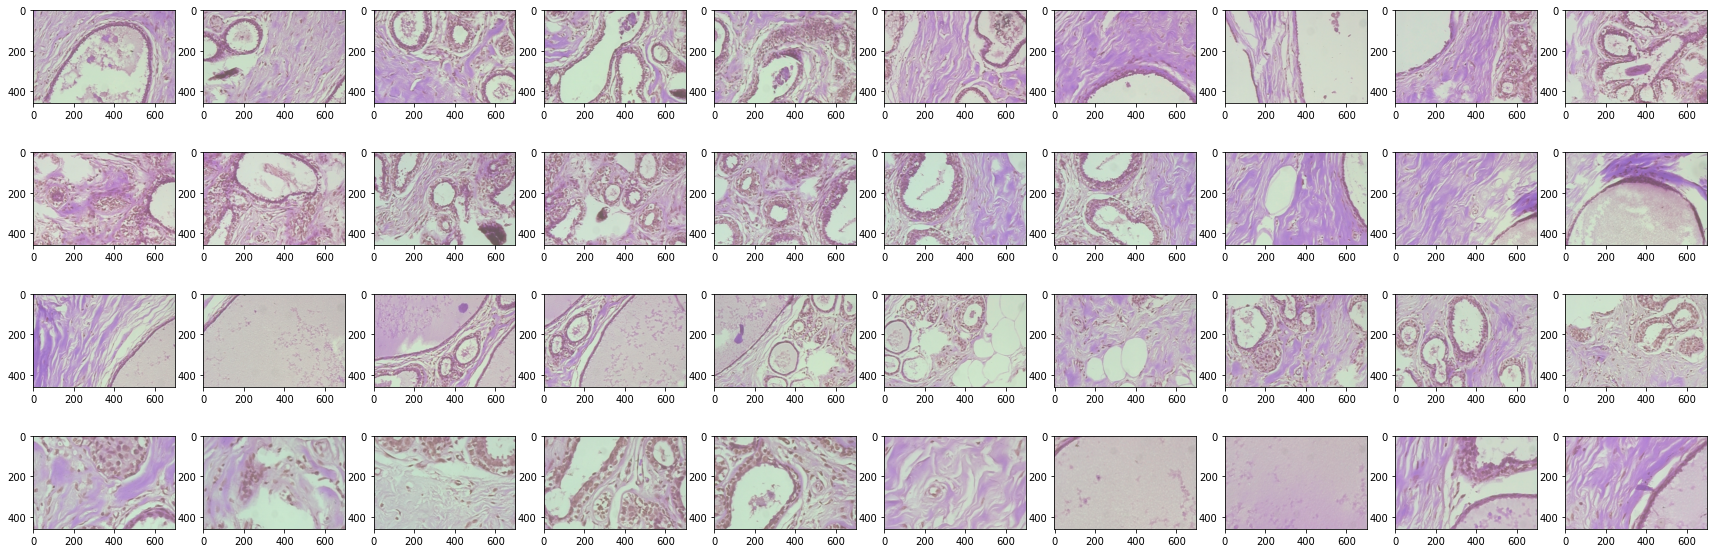

In [18]:
plt.figure(figsize = (30,10))
for i in range(0,40):
    plt.subplot(4,10,i+1)
    img = cv2.imread("../Cancer/"+ benign_df['file_loc'][i],1)
    plt.imshow(img)

# Cancerous Images

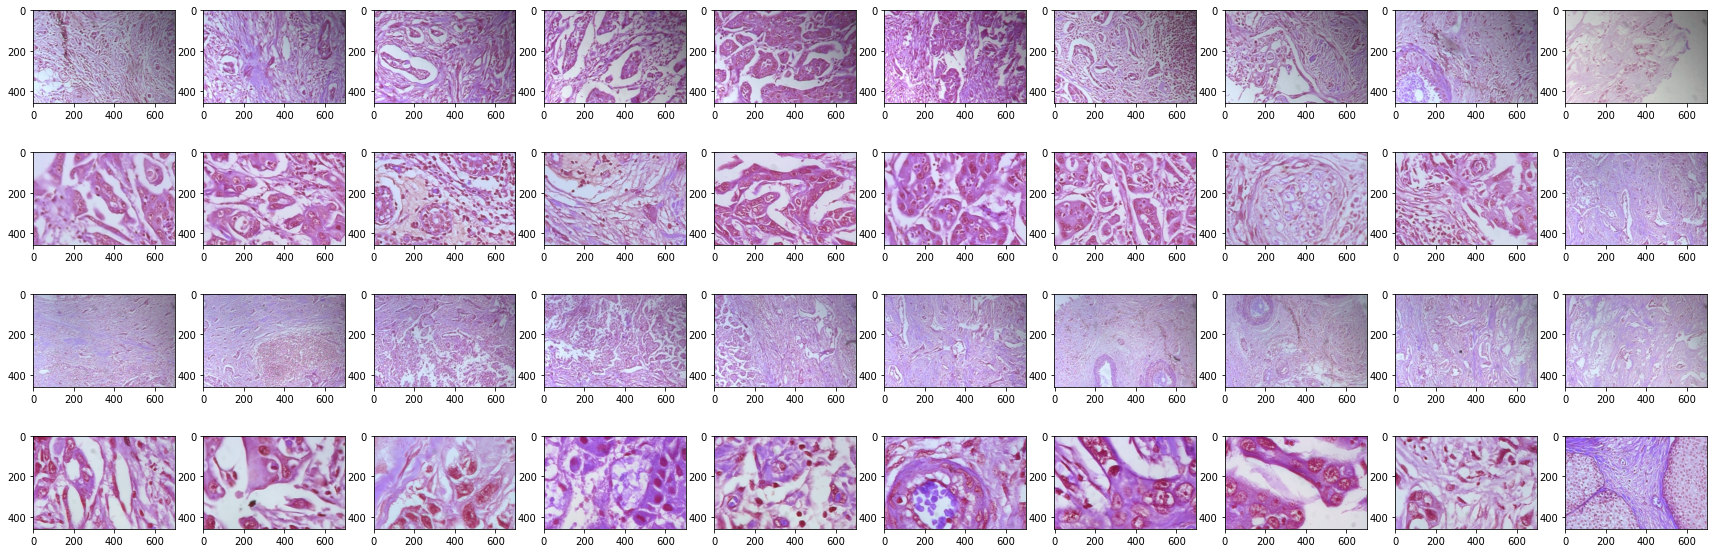

In [19]:
images = malignant_df['file_loc'].values
plt.figure(figsize = (30,10))
for i in range(0,40):
    plt.subplot(4,10,i+1)
    img = cv2.imread("../Cancer/"+ images[i],1)
    plt.imshow(img)

In [20]:
df = pd.DataFrame(os.listdir("../Cancer/"))
df = df.rename(columns = {0:'file_loc'})
df['label'] = df['file_loc'].apply(lambda x:x.split("_")[0])
df['class'] = df['label'].apply(lambda x: 0 if x =='benign' else 1)
df.set_index("file_loc",inplace=True)

In [21]:
import cv2
import numpy as np

IMG_SIZE = 128

def load_images(df, base_path="../Cancer/"):
    images = []
    labels = []
    for filename in df.index:
        img = cv2.imread(base_path + filename)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = img.astype('float32') / 255.0
        images.append(img)
        labels.append(df.loc[filename, 'class'])
    return np.array(images), np.array(labels)

X, y = load_images(df)

In [22]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D

input_img = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)

x = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

autoencoder = Model(input_img, decoded)
autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.fit(X, X, epochs=20, batch_size=32, shuffle=True, validation_split=0.2)


Epoch 1/20
198/198 [==============================] - 75s 372ms/step - loss: 0.0156 - val_loss: 0.0083
Epoch 2/20
198/198 [==============================] - 76s 386ms/step - loss: 0.0074 - val_loss: 0.0062
Epoch 3/20
198/198 [==============================] - 81s 411ms/step - loss: 0.0062 - val_loss: 0.0061
Epoch 4/20
198/198 [==============================] - 72s 364ms/step - loss: 0.0059 - val_loss: 0.0056
Epoch 5/20
198/198 [==============================] - 71s 358ms/step - loss: 0.0055 - val_loss: 0.0052
Epoch 6/20
198/198 [==============================] - 71s 358ms/step - loss: 0.0053 - val_loss: 0.0050
Epoch 7/20
198/198 [==============================] - 71s 359ms/step - loss: 0.0052 - val_loss: 0.0050
Epoch 8/20
198/198 [==============================] - 72s 366ms/step - loss: 0.0051 - val_loss: 0.0049
Epoch 9/20
198/198 [==============================] - 72s 363ms/step - loss: 0.0051 - val_loss: 0.0049
Epoch 10/20
198/198 [==============================] - 73s 369ms/step - l

In [23]:
encoder = Model(inputs=autoencoder.input, outputs=encoded)
X_encoded = encoder.predict(X)
X_flat = X_encoded.reshape((X_encoded.shape[0], -1))

              precision    recall  f1-score   support

           0       0.85      0.68      0.76       522
           1       0.86      0.94      0.90      1060

    accuracy                           0.86      1582
   macro avg       0.86      0.81      0.83      1582
weighted avg       0.86      0.86      0.85      1582



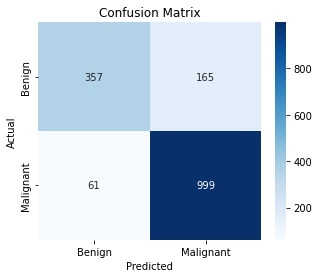

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(X_flat, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(n_estimators=100)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [25]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}")

Accuracy Score: 0.8571


In [29]:
import shap
import numpy as np
from sklearn.utils import resample

X_test_sample, y_test_sample = resample(X_test, y_test, n_samples=int(0.2 * len(X_test)), random_state=42, stratify=y_test)

explainer = shap.TreeExplainer(clf)

shap_values = explainer.shap_values(X_test_sample, check_additivity=False)

feature_importance = np.abs(shap_values[1]).mean(axis=0)

feature_contributions = [(i, importance) for i, importance in enumerate(feature_importance)]

feature_contributions.sort(key=lambda x: x[1], reverse=True)

contribution_array = np.array(feature_contributions)

print("Top 10 contributing features (index, importance):")
print(contribution_array[:10])


Top 10 contributing features (index, importance):
[[ 9913.          2478.0354766 ]
 [11658.          2252.31353624]
 [14041.          2085.84121462]
 [ 1967.          1954.42194591]
 [15328.          1454.15403929]
 [10747.          1319.665782  ]
 [ 2057.          1314.69995715]
 [14657.          1242.50592999]
 [15876.          1095.56687659]
 [15708.          1023.93732518]]


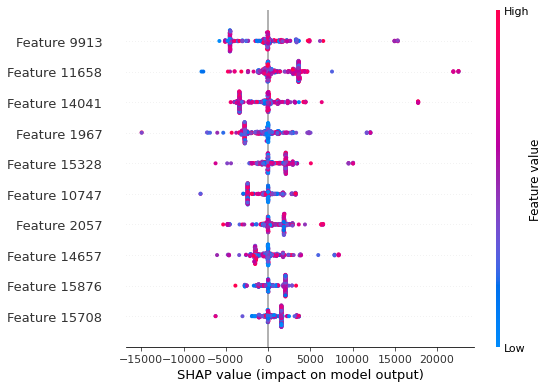

In [30]:
shap.summary_plot(shap_values[1], X_test_sample, max_display=10)


100%|===================| 1578/1582 [01:40<00:00]        

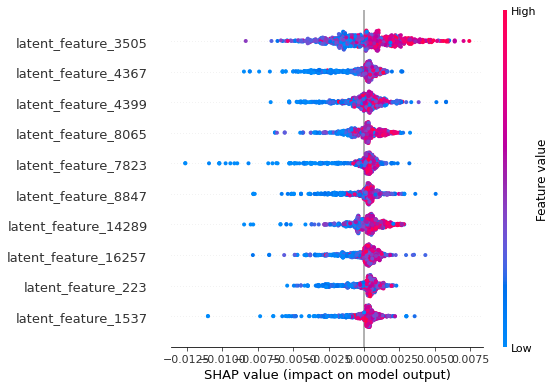


Top 10 latent features contributing to predictions:
                    Feature  Mean_Absolute_SHAP
3505    latent_feature_3505            0.001788
4367    latent_feature_4367            0.001086
4399    latent_feature_4399            0.000958
8065    latent_feature_8065            0.000903
7823    latent_feature_7823            0.000893
8847    latent_feature_8847            0.000870
14289  latent_feature_14289            0.000864
16257  latent_feature_16257            0.000848
223      latent_feature_223            0.000839
1537    latent_feature_1537            0.000816


In [33]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import resample

X_test_sample, y_test_sample = resample(
    X_test, y_test,
    n_samples=int(0.5 * len(X_test)),
    random_state=42,
    stratify=y_test
)

background = shap.utils.sample(X_train, 100, random_state=42)

explainer = shap.TreeExplainer(
    clf,
    data=background,
    model_output="probability",
    feature_perturbation="interventional"
)

shap_values = explainer.shap_values(X_test_sample, check_additivity=False)

num_features = X_test_sample.shape[1]
feature_names = [f"latent_feature_{i}" for i in range(num_features)]

X_test_df = pd.DataFrame(X_test_sample, columns=feature_names)

shap.summary_plot(shap_values[1], X_test_df, max_display=10)

mean_shap = np.abs(shap_values[1]).mean(axis=0)
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_shap
}).sort_values(by="Mean_Absolute_SHAP", ascending=False)

print("\nTop 10 latent features contributing to predictions:")
print(importance_df.head(10))
